# 05 — Regression Modeling (thesis Chapter 6)

**Input:** `data/processed/prescribed_treatment_data_new_clean.csv`. Fires with 0 or 1 acre (`log_incident_acres_burned == 0`)
are dropped, leaving 1,969 fires. 80/20 train/test split stratified by region (`random_state=1`).

| Thesis item | Output |
|---|---|
| Tables 6.1–6.2 VIF | printed |
| Table 6.3 / Fig 6.1 separate regression per region | `figures/region_coef.pdf` |
| Table 6.4 pooled linear regression with region interactions | printed; coefficient plot in `figures/lm_coef.pdf` |
| Figs 6.2–6.5 regression diagnostics | `figures/log_prescribed_3_months_size_50km.pdf`, `tmax.pdf`, `pcp.pdf`, `max_wind.pdf` |
| Table 6.6, Figs 6.6–6.7 linear mixed model (random effects by region) | printed; `figures/lmm_partial_regression.pdf`, `figures/lmm_residuals.pdf` |
| Figs 6.8–6.11 KNN / SVM / RF / AdaBoost feature importance | `figures/knn_…`, `svm_…`, `rf_…`, `ada_feature_importance.pdf` |
| Table 6.7 / Fig 6.12 train & test MSE | printed; `figures/mse_results.pdf` |
| Fig 6.13 predicted vs true | `figures/model_performance.pdf` |

The PyPI build of scikit-learn 1.2.2 (pinned in `environment.yml`) reproduced the 2024 random forest numbers exactly. Keep it pinned so results stay comparable.

**Notes for future work**
* **`max_wind` was corrected in November 2026**, so every table and figure that uses it (Tables 6.1–6.7,
  Figs 6.1, 6.5–6.13) now differs from the submitted thesis. The 2024 values used the first fire's date for every row.
  They now give the maximum wind on the fire's own date (see `01_dataset_creation.ipynb` and `docs/data_dictionary.md`).
  The 2024 outputs of this notebook are in `old/original_notebooks_2024/Modeling_2.ipynb`.
* The OLS models are fit with `hasconst=False` and an explicit `constant` column, so statsmodels reports
  *uncentered* R² (≈0.89). That number is not comparable to the usual R²; compare models by MSE instead.
* Before 2026-11 this notebook saved two different plots to `figures/region_coef.pdf`, and the second overwrote the first.
  The pooled-model coefficient plot now goes to `figures/lm_coef.pdf`.

# Modelling

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("ggplot")
import seaborn as sn
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm
from functions import crosscorrelations_target_single_plot
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score, mean_squared_error


## Preprocessing

In [2]:
df = pd.read_csv("data/processed/prescribed_treatment_data_new_clean.csv", index_col=0)

In [3]:
# 2024 download code, kept for the record. It has a BUG: `date = df["ex_date"][0]` uses the first fire's date for every row.
# Replaced by the corrected download in 01_dataset_creation.ipynb (Wind speed section); do not use.
# wind_speed = []
# for i in range(len(df)):
#     lat = df.at[i,"incident_latitude"]
#     lon = df.at[i,"incident_longitude"]
#     date = df["ex_date"][0].split(" ")[0]
#     url = "https://archive-api.open-meteo.com/v1/archive?latitude="+str(lat)+"&longitude="+str(lon)+"&start_date="+date+"&end_date="+date+"&hourly=wind_speed_10m&format=csv"
#     temp_df = pd.read_csv(url, header=2)
#     max_wind = max(temp_df["wind_speed_10m (km/h)"])
#     wind_speed.append(max_wind)
# df["max_wind"] = wind_speed

In [4]:
df = df.loc[df["log_incident_acres_burned"]!=0].reset_index(drop=True)

In [5]:
df = df.dropna(subset=["region"]).reset_index(drop=True)

In [6]:
fig, axs = plt.subplots(1, 1, figsize=(6,4))
sn.histplot(np.log(df['incident_acres_burned'].replace(0, np.nan)).replace(np.nan, 0), ax=axs, legend=False)
axs.set_xlabel("log(acres burned)")
axs.set_title("Wildfire Size")
axs.set_ylim([0, 250])
axs.set_xlim([0, 14])
plt.tight_layout()
plt.show()

<Figure size 600x400 with 1 Axes>

In [7]:
len(df)

1969

In [8]:
# import numpy as np
# Q1 = np.quantile(df["log_incident_acres_burned"],0.25)
# Q3 = np.quantile(df["log_incident_acres_burned"],0.75)
# IQR = Q3 - Q1
# min_r = Q1 - 1.5*IQR
# max_r = Q3 + 1.5*IQR
# df = df.loc[(df["log_incident_acres_burned"]<max_r) & (df["log_incident_acres_burned"]>min_r)]

In [9]:
df["county_cat"] = pd.factorize(df["region"])[0]
one_hot = pd.get_dummies(df['region'])
df = df.join(one_hot)

In [10]:
regions = df["region"].unique()

In [11]:
df["constant"] = [1 for i in range(len(df))]

In [12]:
# convert rx to log
df["log_rx_12_months_50_km"] = np.log(df["prescribed_12_months_size_50km"].replace(0, np.nan)).replace(np.nan, 0)
rx_cols = [col for col in df.columns if "prescribed" in col]
for col in rx_cols:
    df["log_"+col] = np.log(df[col].replace(0, np.nan)).replace(np.nan, 0)

/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages

In [13]:
potential_features = ["log_incident_acres_burned", 'incident_longitude', 'incident_latitude', 'tavg',
                    'tmin', 'tmax', 'pcp', 'pdsi', 'phdi', 'pmdi',  'zndx', 
                    "prescribed_3_months_size_10km", "prescribed_3_months_size_50km",
                    "prescribed_6_months_size_50km", "prescribed_6_months_size_10km", "max_wind"]

In [14]:
continuous_features = ['incident_longitude', 'incident_latitude',
            'tmax', 'pcp',   'zndx', "max_wind",
            "log_prescribed_3_months_size_50km", "log_prescribed_12_months_size_50km",
             "log_prescribed_6_months_size_50km"]

In [15]:
selected_features = ['zndx', "tmax", "pcp", "log_prescribed_3_months_size_10km", "log_prescribed_3_months_size_50km", "log_prescribed_6_months_size_10km", #"prescribed_6_months_size_50km",
                    "log_prescribed_12_months_size_50km", 'incident_longitude', 'incident_latitude', "max_wind"] 
selected_linear_features = ["pcp", 
    #"log_prescribed_12_months_size_50km", #"zndx",#'incident_longitude', 'incident_latitude',
     "log_prescribed_3_months_size_50km", 
     "tmax",
    "max_wind"
                            ] 
selected_linear_m_features = selected_linear_features

In [16]:
regions

array(['Sierras', 'Desert', 'Central Valley', 'North Coast',
       'Central Coast', 'Multiple', 'South Coast', 'Shasta Cascades'],
      dtype=object)

In [17]:
selected_regions =  ["Sierras", "South Coast", 'Central Coast', "Shasta Cascades", "Multiple"]

In [18]:
# interactions
interactions = []
#regions = list(df["region"].unique())
for region in selected_regions:
    for feature in selected_features:
        df[region+"_X_"+feature] = df[region]*df[feature]
        interactions.append(region+"_X_"+feature)

/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/3456299138.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[region+"_X_"+feature] = df[region]*df[feature]
/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/3456299138.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[region+"_X_"+feature] = df[region]*df[feature]
/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/3456299138.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fram

In [19]:
f_interactions = []
for f1 in selected_linear_features:
    for f2 in selected_linear_features:
        df[f1+"_X_"+f2] = df[f1]*df[f2]
        f_interactions.append(f1+"_X_"+f2)

/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/3641693861.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f1+"_X_"+f2] = df[f1]*df[f2]
/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/3641693861.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f1+"_X_"+f2] = df[f1]*df[f2]
/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/3641693861.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor

In [20]:
interactions_lm = [inter for inter in interactions if any(f in inter for f in selected_linear_features)]
regional_features = ["pcp", 
    #"log_prescribed_12_months_size_50km", #"zndx",#'incident_longitude', 'incident_latitude',
     "log_prescribed_3_months_size_50km", 
     "tmax",
    "max_wind"
                            ] 
selected_linear_features = selected_linear_features + interactions_lm
lmm_features = selected_linear_features + ["constant"]

In [21]:
train_val, test = train_test_split(df, test_size=0.2, train_size=0.8, random_state=1, stratify=df["region"])

kf = KFold(n_splits=5, random_state=123, shuffle=True)

columns_to_encode = list(df["region"].unique())

# min max scale
scaler = StandardScaler().fit(train_val[selected_features].fillna(0).astype(float))
scaled = pd.DataFrame(scaler.transform(train_val[selected_features].fillna(0).astype(float)), columns=selected_features)
encoded = train_val[columns_to_encode].reset_index(drop=True).astype(int)
x_train = pd.concat([scaled, encoded], axis=1)

scaled = pd.DataFrame(scaler.transform(test[selected_features].fillna(0).astype(float)), columns=selected_features)
encoded = test[columns_to_encode].reset_index(drop=True).astype(int)
x_test = pd.concat([scaled, encoded], axis=1)
y_train = train_val["log_incident_acres_burned"].reset_index(drop=True)
y_test = test["log_incident_acres_burned"].reset_index(drop=True)


#  1 v rest: multiple, centeral coast, north coast, sierras.
columns_to_encode = selected_regions#["Sierras", "Central Coast", "Multiple"]
scaler_lm = StandardScaler().fit(train_val[selected_linear_features].fillna(0).astype(float))
scaled = pd.DataFrame(scaler_lm.transform(train_val[selected_linear_features].fillna(0).astype(float)), columns=selected_linear_features)
encoded = train_val[columns_to_encode].reset_index(drop=True).astype(int)
x_train_lm = pd.concat([scaled, encoded], axis= 1)
scaled = pd.DataFrame(scaler_lm.transform(test[selected_linear_features].fillna(0).astype(float)), columns=selected_linear_features)
encoded = test[columns_to_encode].reset_index(drop=True).astype(int)
x_test_lm = pd.concat([scaled, encoded], axis=1)
x_test_lm["constant"] = [1 for i in range(len(y_test))]
x_train_lm["constant"] = [1 for i in range(len(y_train))]
    

In [22]:

models = ["linear regression", "linear mixed effects model",  "random forest", "adaboost"]

In [23]:
# data storage
train_mse = []
test_mse = []

train_r = []
test_r = []

### VIF

In [24]:
vif_data = pd.DataFrame()
input_df = df[continuous_features].fillna(0)
vif_data["feature"] = input_df.columns
vif_data["VIF"] = [variance_inflation_factor(input_df.values, i)
                          for i in range(len(input_df.columns))]
vif_data

,feature,VIF
0,incident_longitude,606.214734
1,incident_latitude,375.176210
2,tmax,110.997896
3,pcp,2.354405
4,zndx,1.794833
5,max_wind,15.289966
6,log_prescribed_3_months_size_50km,4.473669
7,log_prescribed_12_months_size_50km,12.973253
8,log_prescribed_6_months_size_50km,11.686908


In [25]:
print(vif_data.round(3).to_latex())

\begin{tabular}{llr}
\toprule
 & feature & VIF \\
\midrule
0 & incident_longitude & 606.215000 \\
1 & incident_latitude & 375.176000 \\
2 & tmax & 110.998000 \\
3 & pcp & 2.354000 \\
4 & zndx & 1.795000 \\
5 & max_wind & 15.290000 \\
6 & log_prescribed_3_months_size_50km & 4.474000 \\
7 & log_prescribed_12_months_size_50km & 12.973000 \\
8 & log_prescribed_6_months_size_50km & 11.687000 \\
\bottomrule
\end{tabular}



In [26]:
vif_data = pd.DataFrame()
input_df = df[regional_features].fillna(0)
vif_data["feature"] = input_df.columns
vif_data["VIF"] = [variance_inflation_factor(input_df.values, i)
                          for i in range(len(input_df.columns))]
vif_data

,feature,VIF
0,pcp,1.276627
1,log_prescribed_3_months_size_50km,2.121274
2,tmax,13.581944
3,max_wind,12.685609


In [27]:
print(vif_data.round(3).to_latex())

\begin{tabular}{llr}
\toprule
 & feature & VIF \\
\midrule
0 & pcp & 1.277000 \\
1 & log_prescribed_3_months_size_50km & 2.121000 \\
2 & tmax & 13.582000 \\
3 & max_wind & 12.686000 \\
\bottomrule
\end{tabular}



## Linear Regression

In [28]:
y = df["log_incident_acres_burned"]

### Null model

In [29]:
null_model = sm.OLS(y_train, x_train_lm["constant"], missing='drop', hasconst=False).fit()
null_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    OLS Regression Results                                    
==============================================================================================
Dep. Variable:     log_incident_acres_burned   R-squared (uncentered):                   0.860
Model:                                   OLS   Adj. R-squared (uncentered):              0.860
Method:                        Least Squares   F-statistic:                              9700.
Date:                       Wed, 04 Nov 2026   Prob (F-statistic):                        0.00
Time:                               11:15:31   Log-Likelihood:                         -3366.7
No. Observations:                       1575   AIC:                                      6735.
Df Residuals:                           1574   BIC:                                      6741.
Df Model:                                  1                                                  
Covariance Type:                   nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
constant       5.0932      0.052     98.489      0.000       4.992       5.195
==============================================================================
Omnibus:                      306.540   Durbin-Watson:                   2.081
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              541.547
Skew:                           1.216   Prob(JB):                    2.54e-118
Kurtosis:                       4.528   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [30]:
train_mse.append(np.mean(np.power((null_model.predict(x_train_lm["constant"]) - y_train),2)))
test_mse.append(np.mean(np.power((null_model.predict(x_test_lm["constant"]) - y_test),2)))
train_r.append(r2_score(y_train, null_model.predict(x_train_lm["constant"])))
test_r.append(r2_score(y_test, null_model.predict(x_test_lm["constant"])))

### Regional Modeling

In [31]:
regional_features = regional_features + ["constant"]
# data storage
predictor_significance = {region:[] for region in df["region"].unique()}
rtrain_mse = []
rtest_mse = []
rtrain_r = []
rtest_r = []
r_2 = []
models = []
# for each region
for region in df["region"].unique():
    res = {"coefficient":[], "pval":[]}
    # subset train, test
    r_train_val, r_test  = train_val.loc[train_val["region"]==region].reset_index(drop=True), test.loc[test["region"]==region].reset_index(drop=True)
    # min max scale
    scaler = StandardScaler().fit(r_train_val[regional_features].fillna(0).astype(float))
    r_x_train = pd.DataFrame(scaler.transform(r_train_val[regional_features].fillna(0).astype(float)), columns=regional_features)
    r_x_test = pd.DataFrame(scaler.transform(r_test[regional_features].fillna(0).astype(float)), columns=regional_features)
    r_y_train = r_train_val["log_incident_acres_burned"].reset_index(drop=True)
    r_y_test = r_test["log_incident_acres_burned"].reset_index(drop=True)
    r_x_test["constant"] = [1 for i in range(len(r_y_test))]
    r_x_train["constant"] = [1 for i in range(len(r_y_train))]
    # fit model
    linear_model = sm.OLS(r_y_train, r_x_train, missing='drop', hasconst=False).fit()
    # get sig preds
    res["coefficient"] = linear_model.params.values
    res["pval"] = linear_model.pvalues.values
    predictor_significance[region] = res
    r_2.append(linear_model.rsquared)
    # get train error, test error
    rtrain_mse.append(np.mean(np.power((linear_model.predict(r_x_train) - r_y_train),2)))
    rtest_mse.append(np.mean(np.power((linear_model.predict(r_x_test) - r_y_test),2)))
    rtrain_r.append(r2_score(r_y_train, linear_model.predict(r_x_train)))
    rtest_r.append(r2_score(r_y_test, linear_model.predict(r_x_test)))
# display sig preds, train error, test error



In [32]:
pd.DataFrame({"Train MSE": rtrain_mse,
            "Test MSE": rtest_mse,
            # "Train R^2": rtrain_r,
            # "Test R^2": rtest_r,
            "R^2": r_2
            }, index=df["region"].unique()).round(3)

,Train MSE,Test MSE,R^2
Sierras,3.771,6.146,0.880
Desert,2.508,4.249,0.885
Central Valley,2.877,2.978,0.904
North Coast,3.537,3.005,0.863
Central Coast,2.501,3.471,0.902
Multiple,6.472,11.423,0.937
South Coast,3.199,3.885,0.904
Shasta Cascades,4.601,6.462,0.853


/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/3365900139.py:40: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


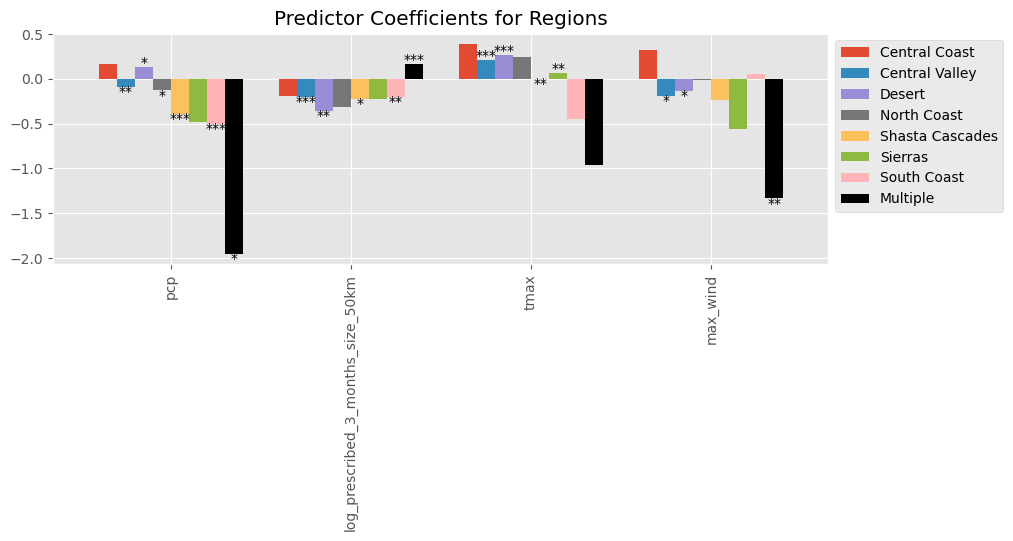

In [33]:
color_dict = {"Central Coast":'#E24A33',
              "Central Valley": '#348ABD',
              "Desert":'#988ED5',
              "North Coast":'#777777',
              "Shasta Cascades":'#FBC15E',
              "Sierras":'#8EBA42',
              "South Coast":'#FFB5B8',
              "Multiple":"#000000"}
reform = {(outerKey, innerKey): values for outerKey, innerDict in predictor_significance.items() for innerKey, values in innerDict.items()}
res = pd.DataFrame(reform, index=regional_features)
res.drop(res.tail(1).index,inplace=True)
res_co = res.loc[:, (slice(None), ["coefficient"])]
res_co.columns = df["region"].unique()
res_co = res_co[color_dict.keys()]
res_co.reset_index()
res_p = res.loc[:, (slice(None), ["pval"])]
res_p.columns = df["region"].unique()
res_p = res_p[color_dict.keys()]
pvals = [res_p.loc[i, c] for i in res_p.index for c in res_p.columns]
sigs = []
for val in pvals:
    if val< 0.01:
        sigs.append("***")
    elif val < 0.05:
        sigs.append("**")
    elif val < 0.1:
        sigs.append("*")
    else:
        sigs.append("")
fig, axs = plt.subplots(1, 1, figsize=(10,3))
res_co.plot.bar(ax=axs, color=color_dict, width=0.8, title="Predictor Coefficients for Regions")

for p, sig in zip(axs.patches,sigs):
    height = p.get_height()
    if p.get_height()<0:
        height = p.get_height() - 0.1
    axs.text(p.get_x() + p.get_width() / 2., height, 
                     sig, ha='center')
plt.legend(bbox_to_anchor=(1,1))
plt.tight_layout()
plt.savefig("figures/region_coef.pdf")
plt.show()

### Model selection

In [34]:
linear_model = sm.OLS(y_train, x_train_lm, missing='drop', hasconst=False).fit()
print(linear_model.summary())

                                    OLS Regression Results                                    
Dep. Variable:     log_incident_acres_burned   R-squared (uncentered):                   0.887
Model:                                   OLS   Adj. R-squared (uncentered):              0.885
Method:                        Least Squares   F-statistic:                              405.7
Date:                       Wed, 04 Nov 2026   Prob (F-statistic):                        0.00
Time:                               11:15:32   Log-Likelihood:                         -3197.7
No. Observations:                       1575   AIC:                                      6455.
Df Residuals:                           1545   BIC:                                      6616.
Df Model:                                 30                                                  
Covariance Type:                   nonrobust                                                  
                                                  

In [35]:
print(linear_model.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}                                             & log\_incident\_acres\_burned & \textbf{  R-squared (uncentered):}      &     0.887   \\
\textbf{Model:}                                                     &             OLS              & \textbf{  Adj. R-squared (uncentered):} &     0.885   \\
\textbf{Method:}                                                    &        Least Squares         & \textbf{  F-statistic:       }          &     405.7   \\
\textbf{Date:}                                                      &       Wed, 04 Nov 2026       & \textbf{  Prob (F-statistic):}          &     0.00    \\
\textbf{Time:}                                                      &           11:15:32           & \textbf{  Log-Likelihood:    }          &   -3197.7   \\
\textbf{No. Observations:}                                          &              1575            & \textbf{  AIC:               }          &     6455.   \\
\textb

In [36]:
linear_model.pvalues [linear_model.pvalues<0.1]

log_prescribed_3_months_size_50km    3.153636e-06
tmax                                 9.701921e-02
Sierras_X_pcp                        2.934212e-02
Sierras_X_max_wind                   1.441338e-03
South Coast_X_tmax                   3.431962e-03
South Coast_X_pcp                    1.233802e-02
Central Coast_X_tmax                 7.980901e-02
Central Coast_X_max_wind             1.338911e-03
Shasta Cascades_X_pcp                9.582494e-02
Multiple_X_pcp                       5.123301e-03
Multiple_X_max_wind                  7.936862e-04
Sierras                              8.704999e-02
South Coast                          7.734913e-03
Central Coast                        8.867858e-03
Multiple                             6.127493e-03
constant                             7.322998e-10
dtype: float64

In [37]:
col_map = [col  if "prescribed" not in col else col.replace("log_prescribed_3_months_size_50km", "RX_3mo_50km") for col in x_train_lm.columns]

In [38]:
res = {}
res["coefficient"] = linear_model.params.values
res["pval"] = linear_model.pvalues.values
res["Predictor"] = col_map

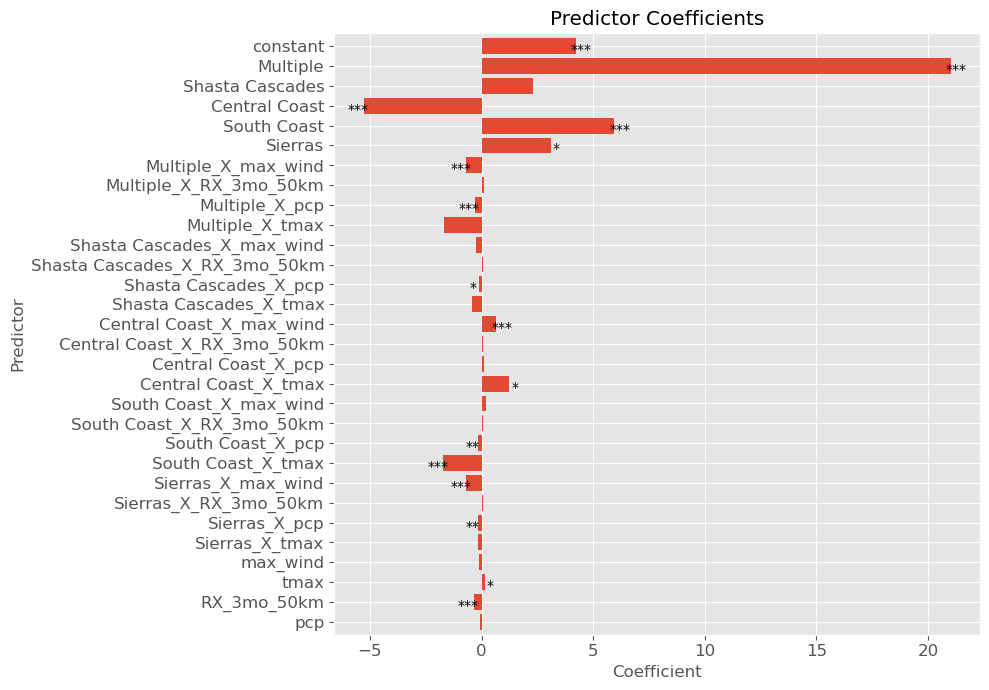

In [39]:
sigs = []
for val in res["pval"]:
    if val< 0.01:
        sigs.append("***")
    elif val < 0.05:
        sigs.append("**")
    elif val < 0.1:
        sigs.append("*")
    else:
        sigs.append("")
res_df = pd.DataFrame(res).set_index("Predictor")
fig, axs = plt.subplots(1, 1, figsize=(10,7))
res_df["coefficient"].plot.barh(ax=axs, width=0.8, title="Predictor Coefficients", fontsize=12)

for p, sig in zip(axs.patches,sigs):
    height = p.get_width()
    if p.get_width()<0:
        height = p.get_width() - 0.25
    else:
        height = height+0.25
    axs.text(height, p.get_y(), 
                     sig, ha='center')
#plt.legend(bbox_to_anchor=(1,1))
axs.set_xlabel("Coefficient")
plt.tight_layout()
plt.savefig("figures/lm_coef.pdf")   # was region_coef.pdf, which overwrote thesis Fig 6.1
plt.show()

In [40]:
# take interaction as 1 vs rest for region/interactions - 1 v rest: multiple, centeral coast, north coast, sierras.
# 

In [41]:
train_mse.append(np.mean(np.power((linear_model.predict(x_train_lm) - y_train),2)))
test_mse.append(np.mean(np.power((linear_model.predict(x_test_lm) - y_test),2)))
train_r.append(r2_score(y_train, linear_model.predict(x_train_lm)))
test_r.append(r2_score(y_test, linear_model.predict(x_test_lm)))

In [42]:
anova_lm(null_model, linear_model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1574.0,6629.645309,0.0,NaN,NaN,NaN
1,1545.0,5348.951385,29.0,1280.693924,12.755785,1.140782e-53


/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/284477795.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/284477795.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/284477795.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35172/284477795.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


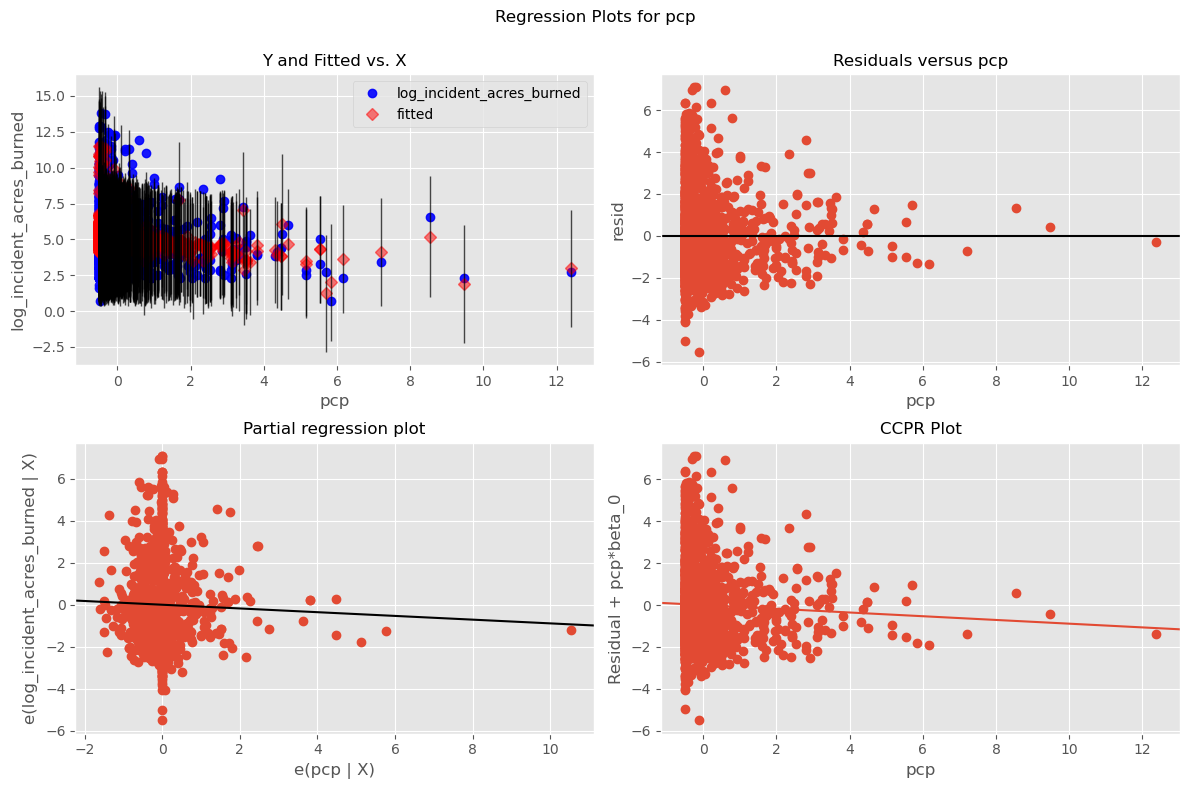

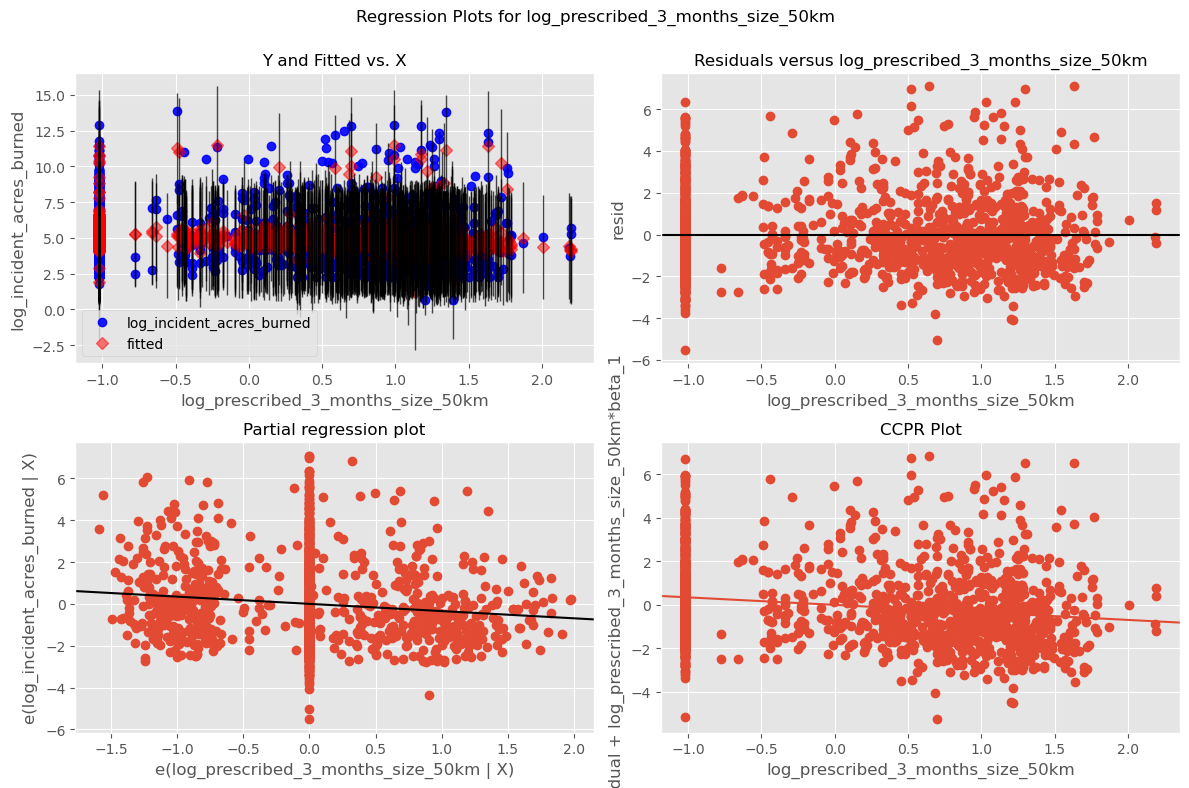

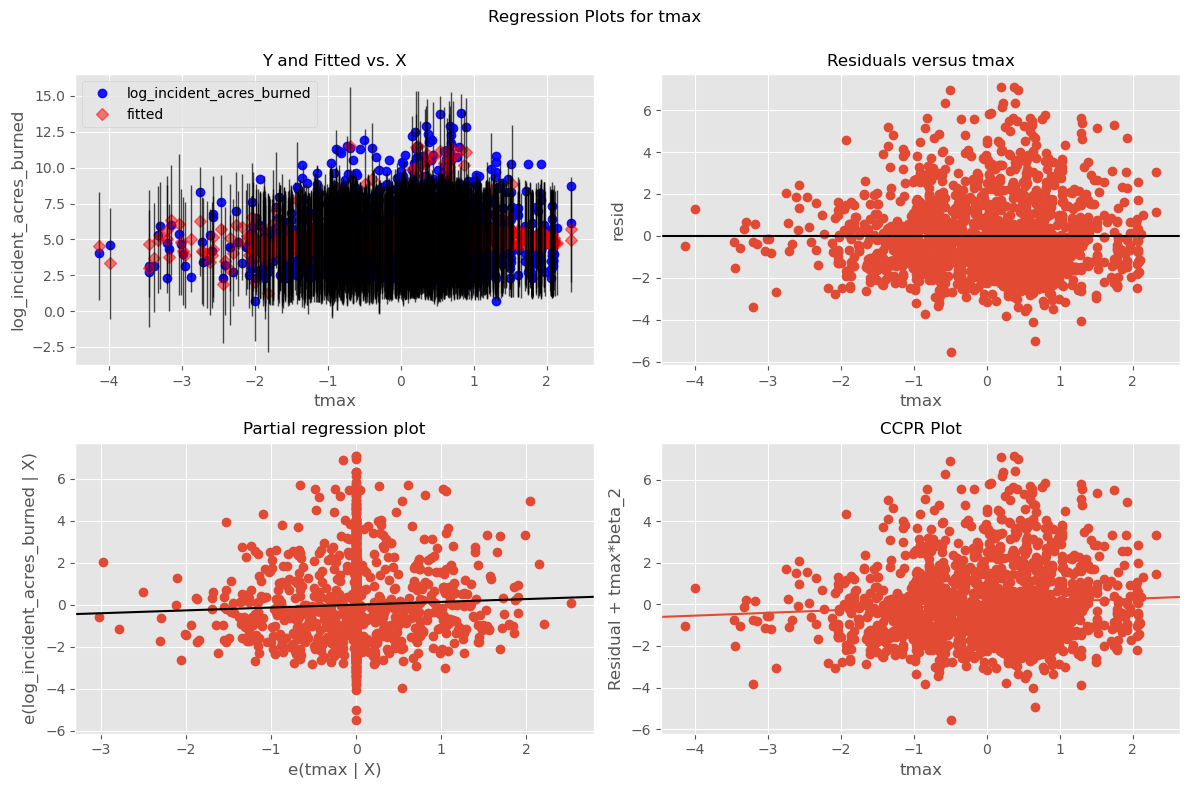

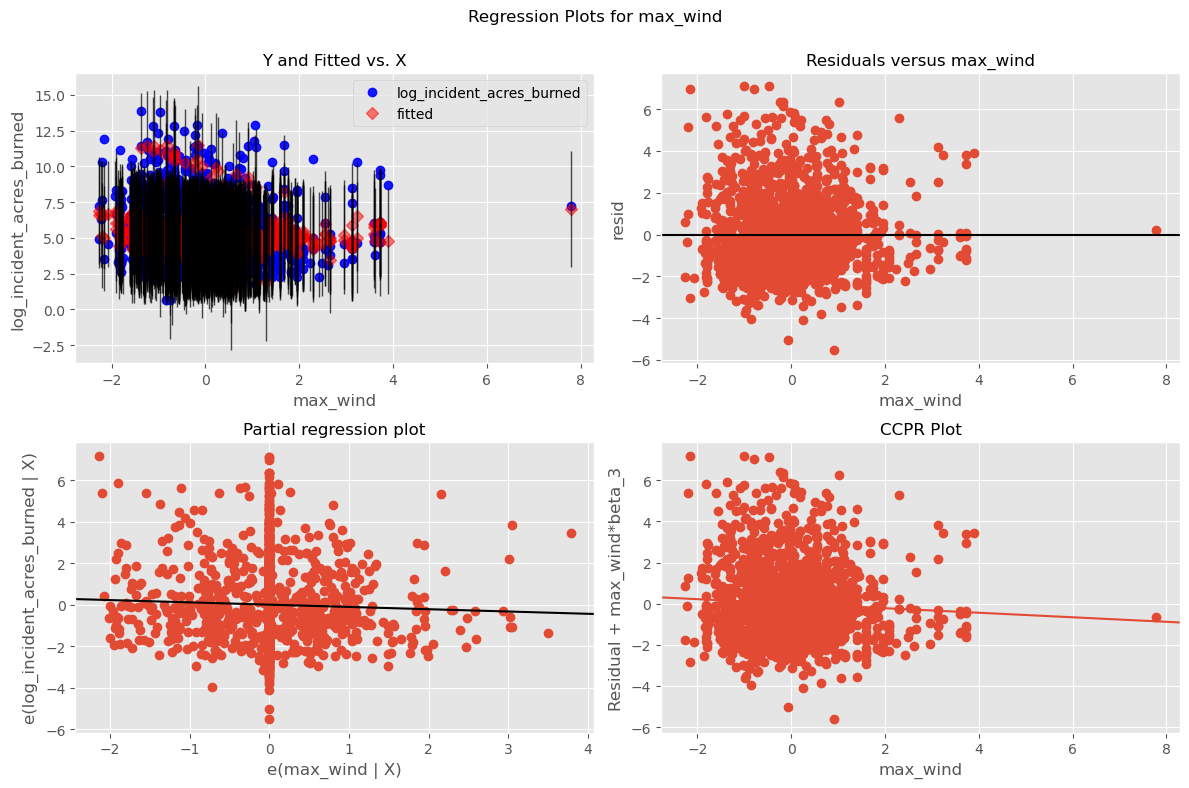

In [43]:
for pred in selected_linear_features:
    if "X" not in pred:
        #define figure size
        fig = plt.figure(figsize=(12,8))
        #produce regression plots
        fig = sm.graphics.plot_regress_exog(linear_model, pred, fig=fig)
        fig.savefig("figures/"+pred+".pdf")
        fig.show()

## Mixed Effects Model

In [44]:
x_train_lmm = pd.concat([x_train_lm[lmm_features].astype(float), train_val[["region"]].reset_index(drop=True), y_train], axis=1).fillna(0)
x_test_lmm = pd.concat([x_test_lm[lmm_features ].astype(float),test[["region"]].reset_index(drop=True)], axis=1).fillna(0)

In [45]:
import statsmodels.formula.api as smf

mm = smf.mixedlm("log_incident_acres_burned ~ pcp + log_prescribed_3_months_size_50km", x_train_lmm, groups="region", 
                 re_formula="~ tmax + max_wind")
mmf = mm.fit()
print(mmf.summary())

                   Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  log_incident_acres_burned
No. Observations:    1575     Method:              REML                     
No. Groups:          8        Scale:               3.4463                   
Min. group size:     34       Log-Likelihood:      -3237.9450               
Max. group size:     341      Converged:           Yes                      
Mean group size:     196.9                                                  
----------------------------------------------------------------------------
                                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------------
Intercept                          4.796    0.311 15.397 0.000  4.185  5.407
pcp                               -0.243    0.047 -5.140 0.000 -0.336 -0.151
log_prescribed_3_months_size_50km -0.248    0.051 -4.894 0.000 -0.347 -0.149
region Var         

/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


In [46]:
print(mmf.summary().as_latex())

\begin{table}
\caption{Mixed Linear Model Regression Results}
\label{}
\begin{center}
\begin{tabular}{llll}
\hline
Model:            & MixedLM & Dependent Variable: & log\_incident\_acres\_burned  \\
No. Observations: & 1575    & Method:             & REML                          \\
No. Groups:       & 8       & Scale:              & 3.4463                        \\
Min. group size:  & 34      & Log-Likelihood:     & -3237.9450                    \\
Max. group size:  & 341     & Converged:          & Yes                           \\
Mean group size:  & 196.9   &                     &                               \\
\hline
\end{tabular}
\end{center}

\begin{center}
\begin{tabular}{lrrrrrr}
\hline
                                       &  Coef. & Std.Err. &      z & P$> |$z$|$ & [0.025 & 0.975]  \\
\hline
Intercept                              &  4.796 &    0.311 & 15.397 &       0.000 &  4.185 &  5.407  \\
pcp                                    & -0.243 &    0.047 & -5.140 &       0.0

In [47]:
 2.872 / 3.4463 

0.8333575138554391

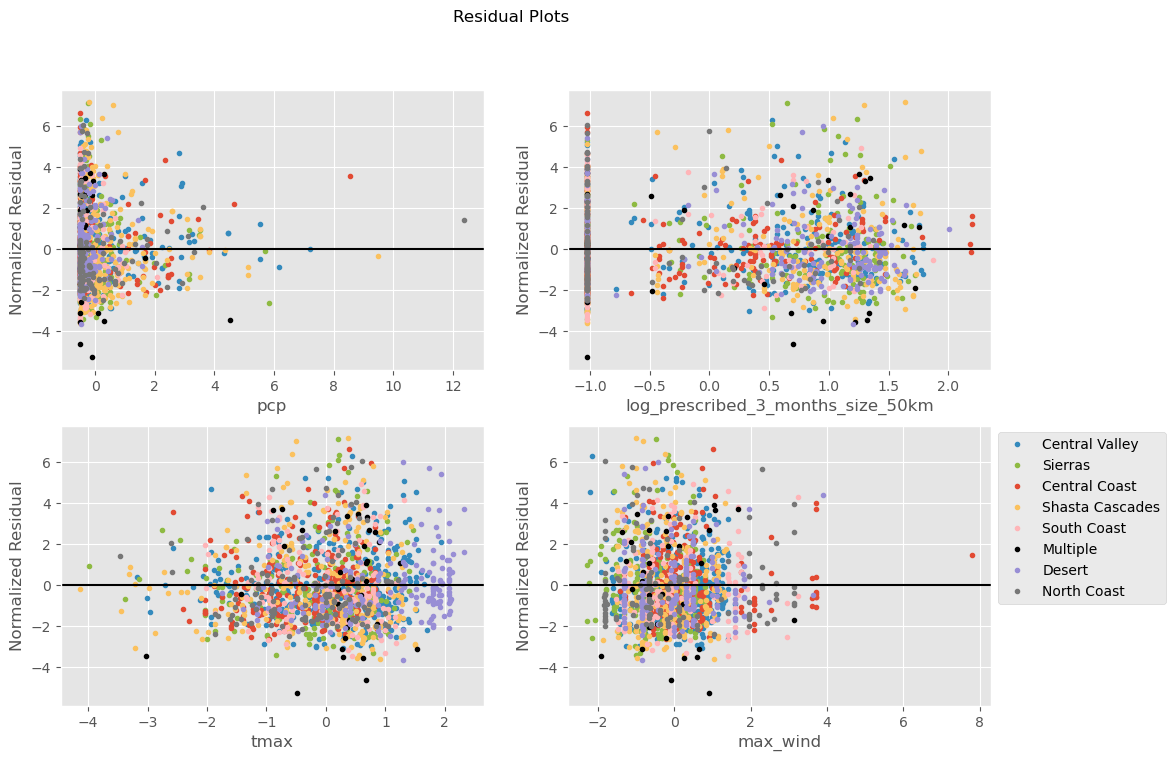

In [48]:
# for each predictor, plot the partial regression for each group color coded with points
#partial regression:
#predict on full x to get y, plot y with x axis, plot points
y_pred = mmf.predict(x_train_lmm)
fig, axs = plt.subplots(2,2, figsize=(12,8))
plt.suptitle("Residual Plots")
i = 0
j = 0
color_dict = {"Central Coast":'#E24A33',
              "Central Valley": '#348ABD',
              "Desert":'#988ED5',
              "North Coast":'#777777',
              "Shasta Cascades":'#FBC15E',
              "Sierras":'#8EBA42',
              "South Coast":'#FFB5B8',
              "Multiple":"#000000"}
for predictor in ["pcp", "log_prescribed_3_months_size_50km", "tmax", "max_wind"]:
    y = mmf.resid.tolist()
    x = x_train_lmm[predictor].tolist()
    point_labels = train_val["region"].tolist()
    for l in set(point_labels):
        x_l = [x[i] for i in range(len(x)) if point_labels[i] == l]
        y_l = [y[i] for i in range(len(y)) if point_labels[i] == l]
        axs[i,j].plot(x_l,y_l,'o',label = l, color=color_dict[l], markersize=3) # plot points
    axs[i,j].axhline(y=0, color='black')
    axs[i,j].set_xlabel(predictor)
    axs[i,j].set_ylabel("Normalized Residual")
    j = j + 1
    if j==2:
        j = 0
        i = i +1
    # axs[i,j].plot(x, y, label=point_labels)
#axs[1,1].remove()
plt.legend(bbox_to_anchor=(1,1))
plt.savefig("figures/lmm_residuals.pdf", bbox_inches="tight")
plt.show()

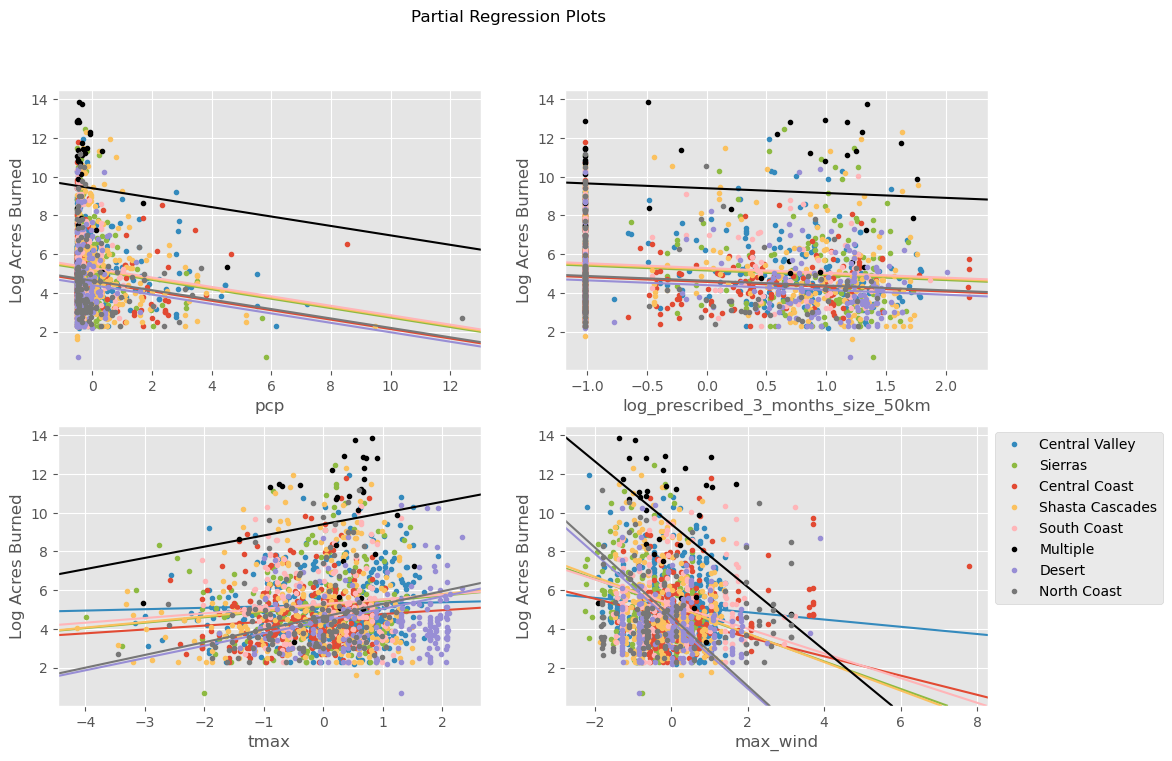

In [49]:
# for each predictor, plot the partial regression for each group color coded with points
#partial regression:
#predict on full x to get y, plot y with x axis, plot points
y_pred = mmf.predict(x_train_lmm)
fig, axs = plt.subplots(2,2, figsize=(12,8))
plt.suptitle("Partial Regression Plots")
i = 0
j = 0
color_dict = {"Central Coast":'#E24A33',
              "Central Valley": '#348ABD',
              "Desert":'#988ED5',
              "North Coast":'#777777',
              "Shasta Cascades":'#FBC15E',
              "Sierras":'#8EBA42',
              "South Coast":'#FFB5B8',
              "Multiple":"#000000"}
for predictor in ["pcp", "log_prescribed_3_months_size_50km", "tmax", "max_wind"]:
    y = x_train_lmm["log_incident_acres_burned"].tolist()
    x = x_train_lmm[predictor].tolist()
    point_labels = train_val["region"].tolist()
    intercept = mmf.params["Intercept"]
    slope = 0
    if predictor not in ["tmax", "max_wind"]:
        slope = mmf.params[predictor]
    for l in set(point_labels):
        g_int = mmf.random_effects[l]["region"] + intercept
        if predictor in ["tmax", "max_wind"]:
            slope = slope + mmf.random_effects[l][predictor]
        x_l = [x[i] for i in range(len(x)) if point_labels[i] == l]
        y_l = [y[i] for i in range(len(y)) if point_labels[i] == l]
        y_pred_l = [y_pred[i] for i in range(len(y)) if point_labels[i] == l]
        axs[i,j].plot(x_l,y_l,'o',label = l, color=color_dict[l], markersize=3) # plot points
        axs[i,j].axline((0, g_int), slope=slope, color=color_dict[l])
    axs[i,j].set_xlabel(predictor)
    axs[i,j].set_ylabel("Log Acres Burned")
    j = j + 1
    if j==2:
        j = 0
        i = i +1
    # axs[i,j].plot(x, y, label=point_labels)
#axs[1,1].remove()
plt.legend(bbox_to_anchor=(1,1))
plt.savefig("figures/lmm_partial_regression.pdf", bbox_inches="tight")
plt.show()

In [50]:
# residuals for each predictor, groups color coded?

In [51]:
mm1 = smf.mixedlm("log_incident_acres_burned ~ pcp + log_prescribed_3_months_size_50km + max_wind", x_train_lmm, groups="region", 
                 re_formula="~tmax")
mmf1 = mm1.fit()
print(mmf1.summary())

                   Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  log_incident_acres_burned
No. Observations:    1575     Method:              REML                     
No. Groups:          8        Scale:               3.5209                   
Min. group size:     34       Log-Likelihood:      -3250.9802               
Max. group size:     341      Converged:           Yes                      
Mean group size:     196.9                                                  
----------------------------------------------------------------------------
                                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------------
Intercept                          4.767    0.895  5.324 0.000  3.012  6.521
pcp                               -0.253    0.063 -3.993 0.000 -0.378 -0.129
log_prescribed_3_months_size_50km -0.260    0.051 -5.084 0.000 -0.360 -0.159
max_wind           

In [52]:
mm2 = smf.mixedlm("log_incident_acres_burned ~ pcp + log_prescribed_3_months_size_50km + max_wind", x_train_lmm, groups="region", 
                 re_formula="~pcp")
mmf2 = mm2.fit()
print(mmf2.summary())

                   Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  log_incident_acres_burned
No. Observations:    1575     Method:              REML                     
No. Groups:          8        Scale:               3.5116                   
Min. group size:     34       Log-Likelihood:      -3247.5654               
Max. group size:     341      Converged:           Yes                      
Mean group size:     196.9                                                  
----------------------------------------------------------------------------
                                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------------
Intercept                          5.533    0.576  9.603 0.000  4.403  6.662
pcp                               -0.362    0.125 -2.900 0.004 -0.606 -0.117
log_prescribed_3_months_size_50km -0.252    0.050 -5.032 0.000 -0.350 -0.154
max_wind           

/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


In [53]:
train_mse.append(np.mean(np.power((mmf.predict(x_train_lmm) - y_train),2)))
test_mse.append(np.mean(np.power((mmf.predict(x_test_lmm) - y_test),2)))
train_r.append(r2_score(y_train, mmf.predict(x_train_lmm)))
test_r.append(r2_score(y_test, mmf.predict(x_test_lmm)))

In [54]:
# group re
2.803/3.5277

0.7945686991524222

In [55]:
# rx re
0.150/4.0325

0.037197768133911964

## Spatial Linear Model

## KNN

In [56]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor

param_grid={'n_neighbors': [3,5,11,15,17], 
            'weights': ["uniform", "distance"],
            }
knn = GridSearchCV(KNeighborsRegressor(), param_grid, cv=kf, scoring='neg_mean_squared_error')
knn = knn.fit(x_train, y_train)
knn.best_params_

{'n_neighbors': 15, 'weights': 'uniform'}

In [57]:
knn = knn.best_estimator_
knn = knn.fit(x_train, y_train)
train_mse.append(np.mean(np.power((knn.predict(x_train) - y_train),2)))
test_mse.append(np.mean(np.power((knn.predict(x_test) - y_test),2)))
train_r.append(r2_score(y_train, knn.predict(x_train)))
test_r.append(r2_score(y_test, knn.predict(x_test)))

In [58]:
np.mean(np.power((knn.predict(x_train) - y_train),2))

3.380403420648377

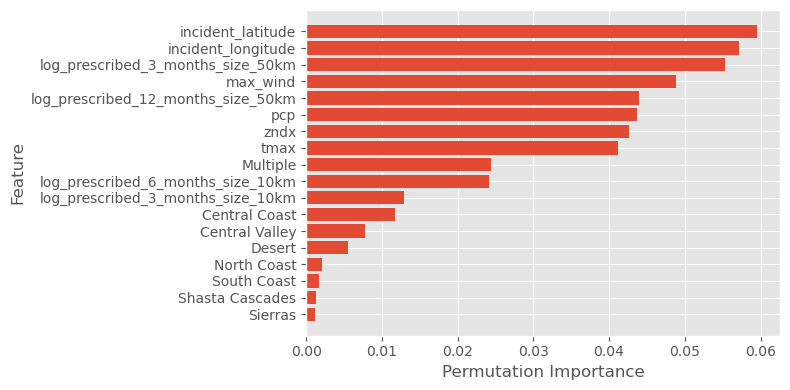

In [59]:
from sklearn.inspection import permutation_importance
perm_importance = permutation_importance(knn, x_train, y_train)

feature_names = list(x_train.columns)
features = np.array(feature_names)

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(8,4))
plt.barh(features[sorted_idx], perm_importance.importances_mean[sorted_idx])
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/knn_feature_importance.pdf")
plt.show()

### SVM

In [60]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

param_grid={'kernel': ['linear', 'poly', 'rbf'], 
            'C': [1e-3, 1e-2, 1e-1, 1, 10],
            }
svm = GridSearchCV(SVR(), param_grid, cv=kf, scoring='neg_mean_squared_error')
svm = svm.fit(x_train, y_train)
svm.best_params_

{'C': 1, 'kernel': 'linear'}

In [61]:
svm = svm.best_estimator_
svm = svm.fit(x_train, y_train)
train_mse.append(np.mean(np.power((svm.predict(x_train) - y_train),2)))
test_mse.append(np.mean(np.power((svm.predict(x_test) - y_test),2)))
train_r.append(r2_score(y_train, svm.predict(x_train)))
test_r.append(r2_score(y_test, svm.predict(x_test)))

In [62]:
# feat_importances = pd.Series(svm.coef_[0], index=svm.feature_names_in_)
# feat_importances.nlargest(10).plot(kind='barh').invert_yaxis()
# plt.xlabel("Coefficient")
# plt.ylabel("Feature")
# plt.tight_layout()
#plt.savefig("svm_feature_importance.pdf")

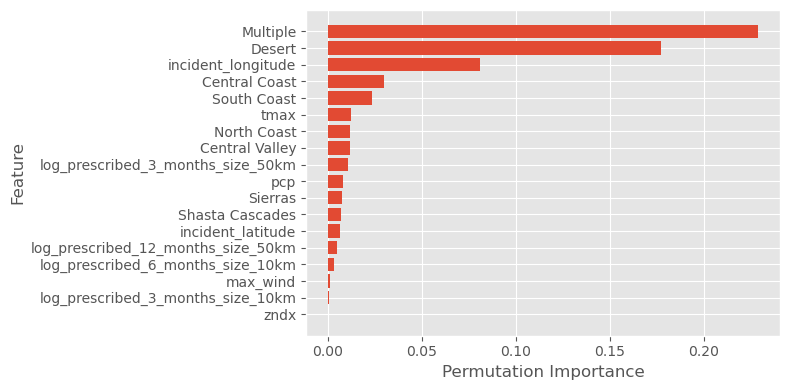

In [63]:
perm_importance = permutation_importance(svm, x_train, y_train)
feature_names = list(x_train.columns)
features = np.array(feature_names)

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(8,4))
plt.barh(features[sorted_idx], perm_importance.importances_mean[sorted_idx])
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/svm_feature_importance.pdf")
plt.show()

## Tree-based Models

In [64]:
# random forest
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid={'n_estimators': [100, 250, 500, 750, 1000], "max_features":["sqrt", "log2", None], "random_state":[123]}
rf = GridSearchCV(RandomForestRegressor(), param_grid, cv=kf, scoring='neg_mean_squared_error')
rf = rf.fit(x_train, y_train)
rf.get_params()

{'cv': KFold(n_splits=5, random_state=123, shuffle=True),
 'error_score': nan,
 'estimator__bootstrap': True,
 'estimator__ccp_alpha': 0.0,
 'estimator__criterion': 'squared_error',
 'estimator__max_depth': None,
 'estimator__max_features': 1.0,
 'estimator__max_leaf_nodes': None,
 'estimator__max_samples': None,
 'estimator__min_impurity_decrease': 0.0,
 'estimator__min_samples_leaf': 1,
 'estimator__min_samples_split': 2,
 'estimator__min_weight_fraction_leaf': 0.0,
 'estimator__n_estimators': 100,
 'estimator__n_jobs': None,
 'estimator__oob_score': False,
 'estimator__random_state': None,
 'estimator__verbose': 0,
 'estimator__warm_start': False,
 'estimator': RandomForestRegressor(),
 'n_jobs': None,
 'param_grid': {'n_estimators': [100, 250, 500, 750, 1000],
  'max_features': ['sqrt', 'log2', None],
  'random_state': [123]},
 'pre_dispatch': '2*n_jobs',
 'refit': True,
 'return_train_score': False,
 'scoring': 'neg_mean_squared_error',
 'verbose': 0}

In [65]:
rf = rf.best_estimator_
rf = rf.fit(x_train, y_train)
train_mse.append(np.mean(np.power((rf.predict(x_train) - y_train),2)))
test_mse.append(np.mean(np.power((rf.predict(x_test) - y_test),2)))
train_r.append(r2_score(y_train, rf.predict(x_train)))
test_r.append(r2_score(y_test, rf.predict(x_test)))

In [66]:
rf

RandomForestRegressor(max_features='sqrt', n_estimators=1000, random_state=123)

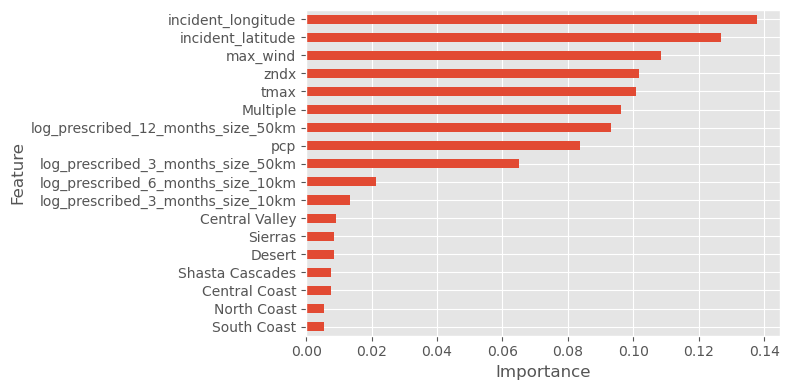

In [67]:
feat_importances = pd.Series(rf.feature_importances_, index=x_train.columns)
feat_importances.nlargest(len(x_train.columns)).plot(kind='barh', figsize=(8,4)).invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/rf_feature_importance.pdf")

In [68]:
# adaboost
from sklearn.ensemble import AdaBoostRegressor
param_grid={'n_estimators': [50, 100, 200, 300, 400, 500], "random_state":[123]}
boost = GridSearchCV(AdaBoostRegressor(), param_grid, cv=kf, scoring='neg_mean_squared_error')
boost = boost.fit(x_train, y_train)
boost.best_estimator_


AdaBoostRegressor(random_state=123)

In [69]:
boost = boost.best_estimator_
boost = boost.fit(x_train, y_train)
train_mse.append(np.mean(np.power((boost.predict(x_train) - y_train),2)))
test_mse.append(np.mean(np.power((boost.predict(x_test) - y_test),2)))
train_r.append(r2_score(y_train, boost.predict(x_train)))
test_r.append(r2_score(y_test, boost.predict(x_test)))

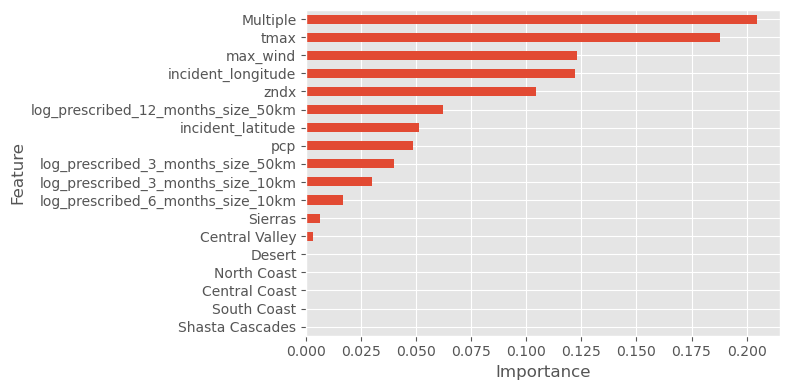

In [70]:
feat_importances = pd.Series(boost.feature_importances_, index=x_train.columns)
feat_importances.nlargest(len(x_train.columns)).plot(kind='barh', figsize=(8,4)).invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/ada_feature_importance.pdf")

## Comparison

In [71]:
models = ["null model", "linear regression", "linear mixed effects model", "KNN", "SVM", "random forest", "adaboost"]

In [72]:
results = pd.DataFrame({"Train MSE": train_mse,
                        "Test MSE": test_mse,
                        # "Train R^2": train_r,
                        # "Test R^2": test_r
                        }, index=models).round(3)

In [73]:
pd.DataFrame({"Train MSE": train_mse,
                        "Test MSE": test_mse
                        # "Train R^2": train_r,
                        # "Test R^2": test_r
                        }, index=models).round(3)

,Train MSE,Test MSE
null model,4.209,4.857
linear regression,3.396,4.467
linear mixed effects model,4.187,5.066
KNN,3.380,4.847
SVM,3.594,4.734
random forest,0.484,4.216
adaboost,4.006,4.749


In [74]:
np.sqrt(np.exp(4.216))

8.231761287547819

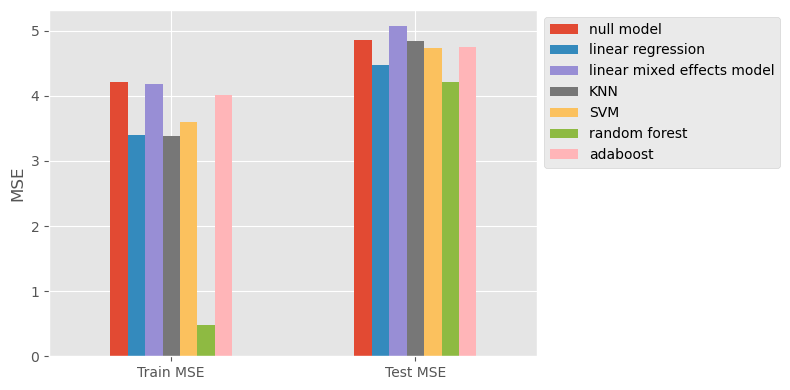

In [75]:
results.T.plot.bar(rot=0,  ylabel="MSE", figsize=(8,4)).legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig("figures/mse_results.pdf")

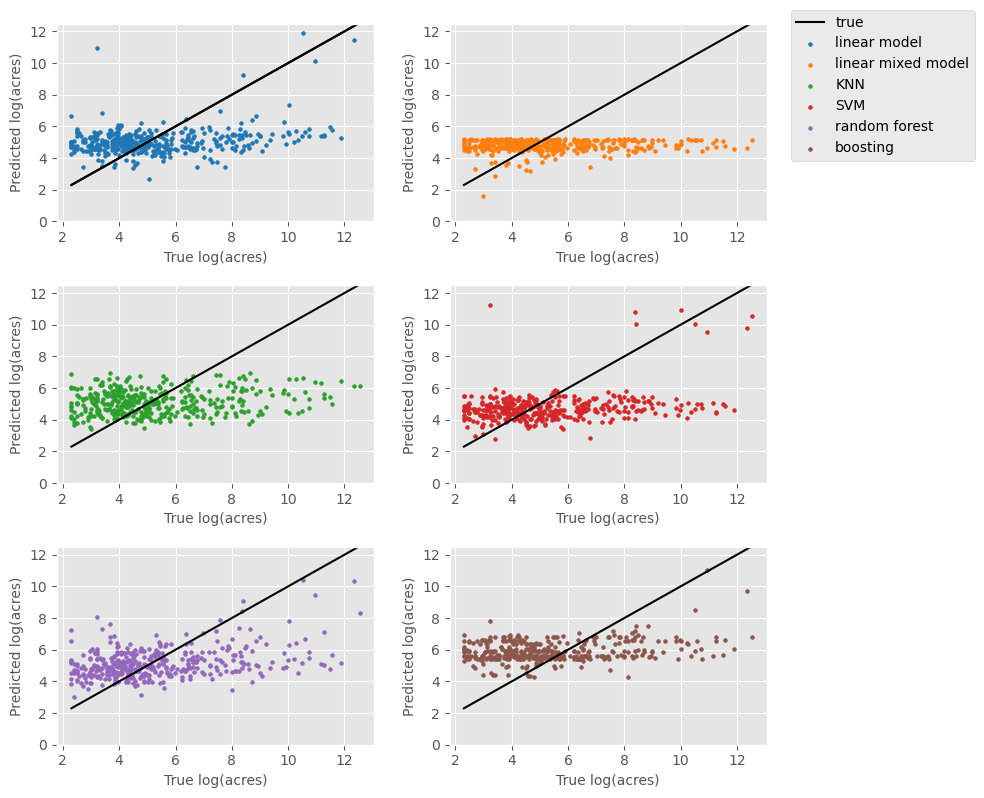

In [76]:
# plot true vs pred for each model
import matplotlib.cm as cm

linear_test = linear_model.predict(x_test_lm)
rf_test = rf.predict(x_test)
boost_test = boost.predict(x_test)
lm_test = mmf.predict(x_test_lmm)
knn_test = knn.predict(x_test)
svm_test = svm.predict(x_test)

errors_df = pd.DataFrame({"True log(acres)":y_test, "linear model":linear_test, "linear mixed model": lm_test, "KNN": knn_test, "SVM": svm_test,
                            "random forest": rf_test, "boosting": boost_test
                          })
errors_df.sort_values("True log(acres)", inplace=True)

#fig = plt.figure()
fig, axs = plt.subplots(3, 2, figsize=(8,8))
row = 0
col = 0
colors =  cm.tab10(np.linspace(0, 1, 10))
c = 0
for mod in errors_df.columns:
    if mod != "True log(acres)":
        if c == 0: axs[row, col].plot(errors_df["True log(acres)"], errors_df["True log(acres)"], label="true", color="black")
        axs[row, col].scatter(errors_df["True log(acres)"], errors_df[mod], label=mod, s=7, color=colors[c])
        axs[row, col].set_xlabel("True log(acres)", fontsize=10)
        axs[row, col].set_ylabel("Predicted log(acres)", fontsize=10)
        col = col + 1
        c = c +1
        if col == 2:
            col = 0
            row = row + 1

lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
row = 0
col = 0
for mod in errors_df.columns:
    if mod != "True log(acres)":
        axs[row, col].plot(errors_df["True log(acres)"], errors_df["True log(acres)"], label="true", color="black")
        axs[row, col].set_ylim(0, 12.5)
        col = col + 1
        if col == 2:
            col = 0
            row = row + 1

fig.legend(lines, labels,bbox_to_anchor=(1.25, 1), loc="upper right")
plt.tight_layout()
plt.savefig("figures/model_performance.pdf")
plt.show()

In [77]:
# shape of point for regions 

/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/statsmodels/graphics/gofplots.py:1041: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  ax.plot(x, y, fmt, **plot_style)


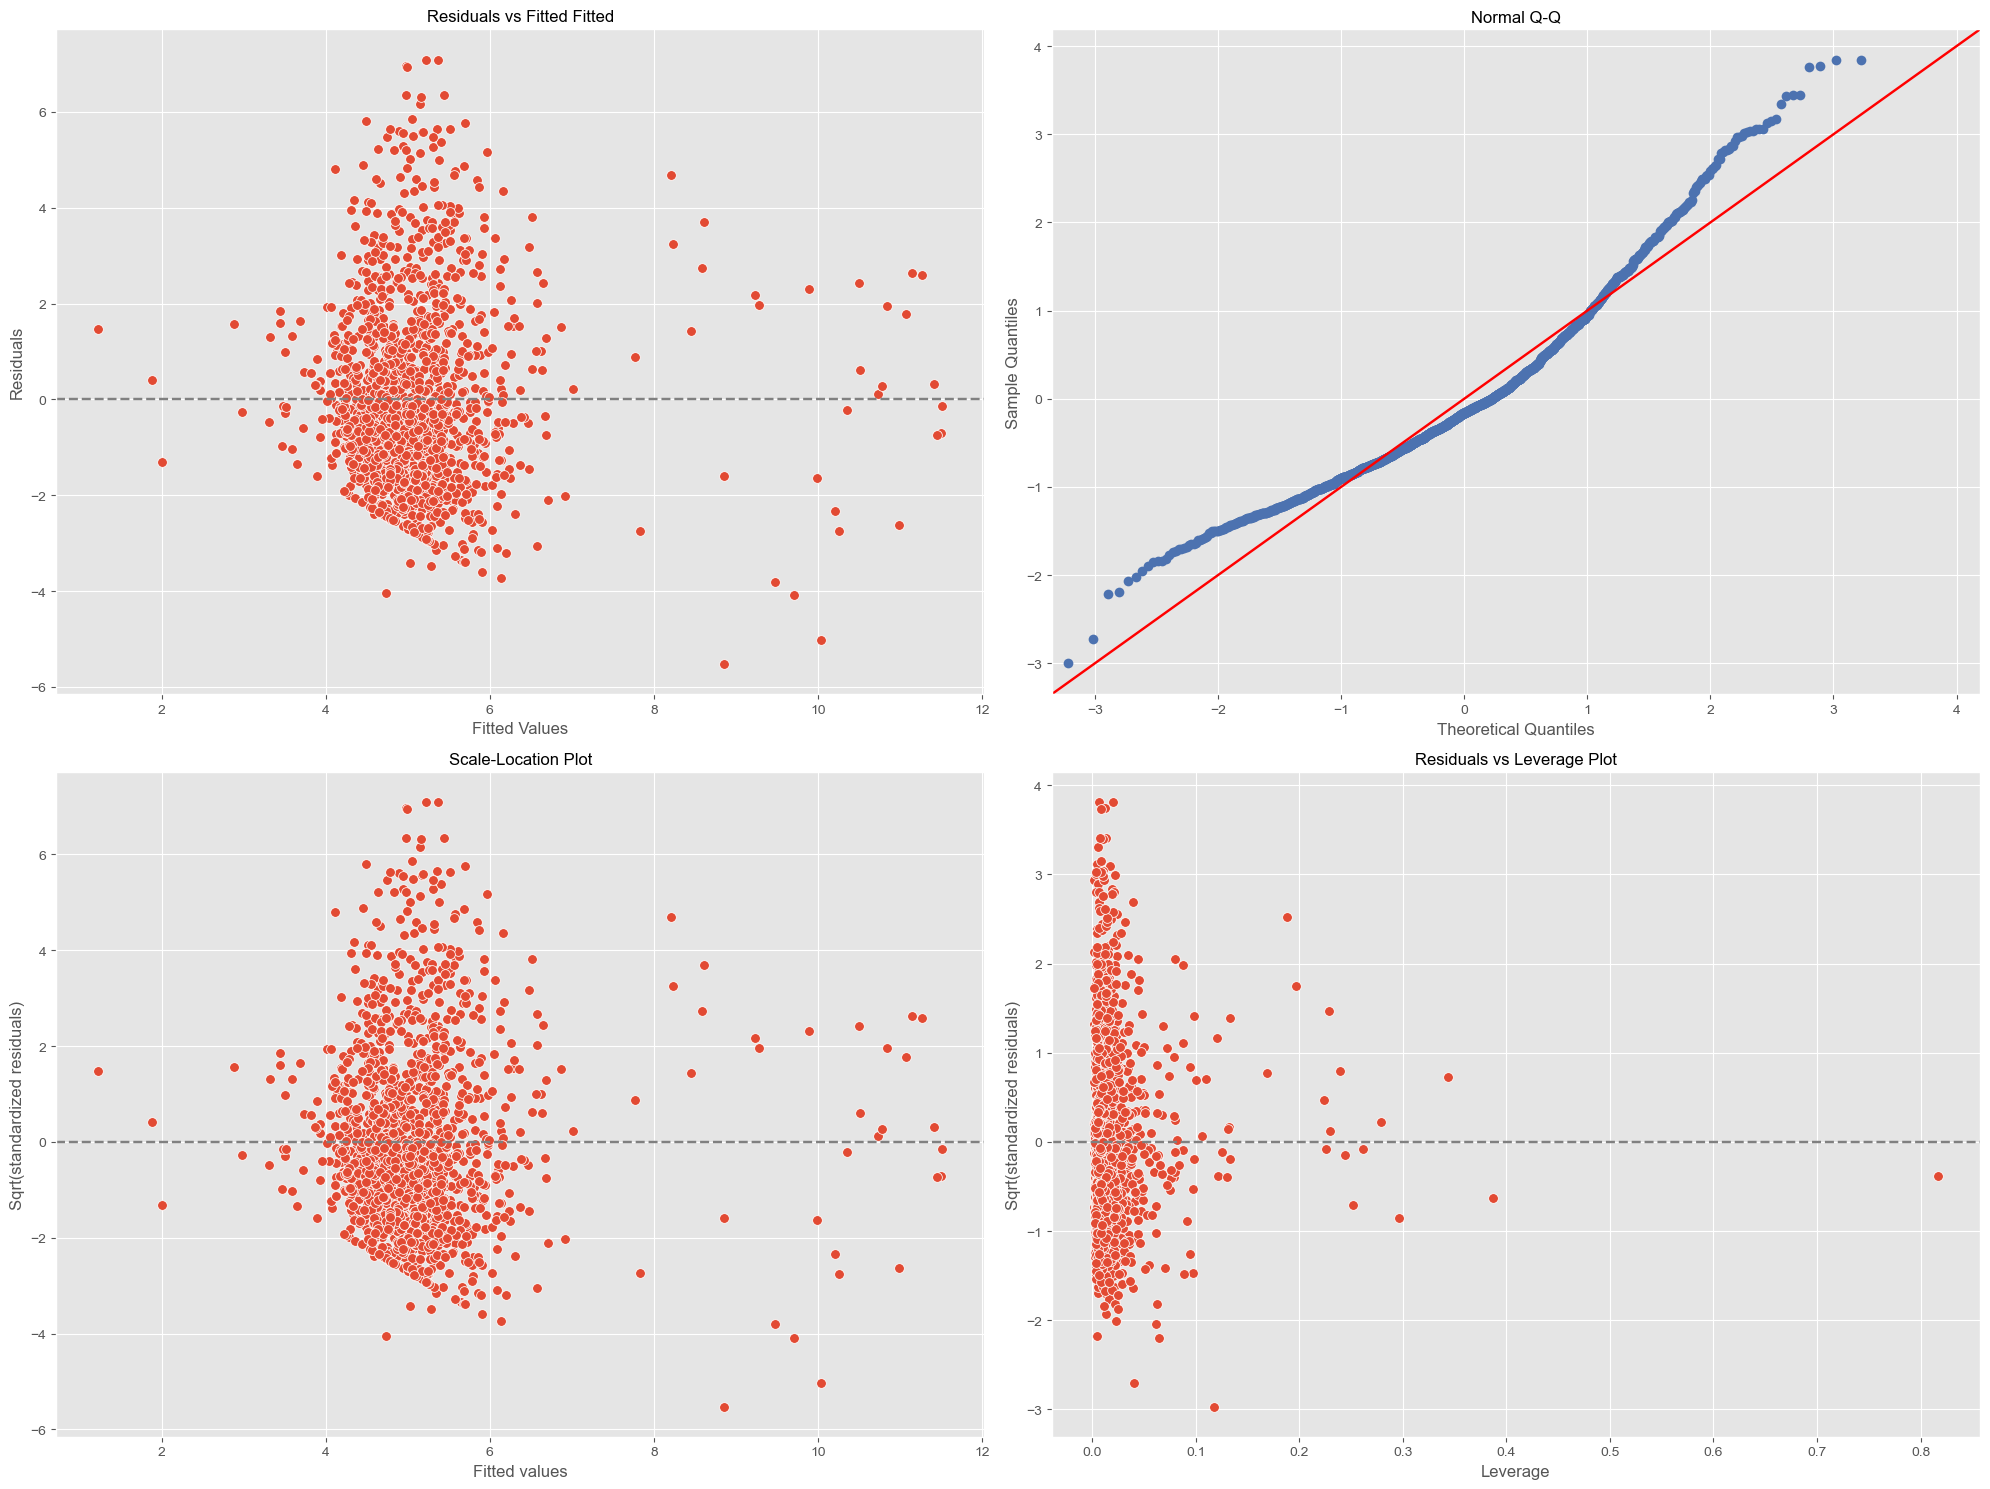

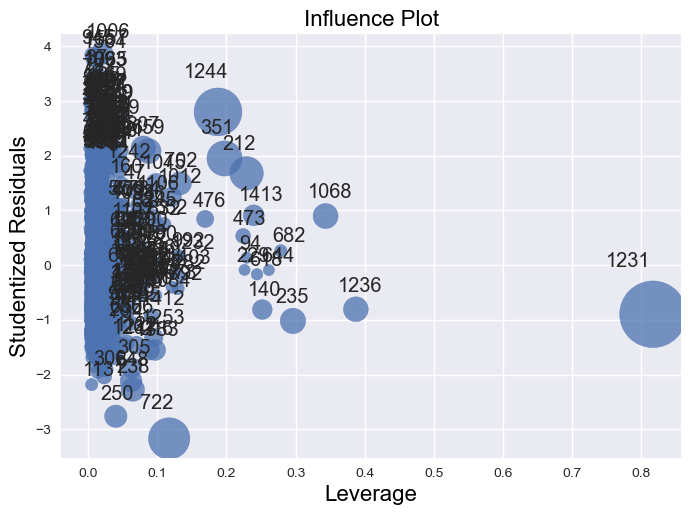

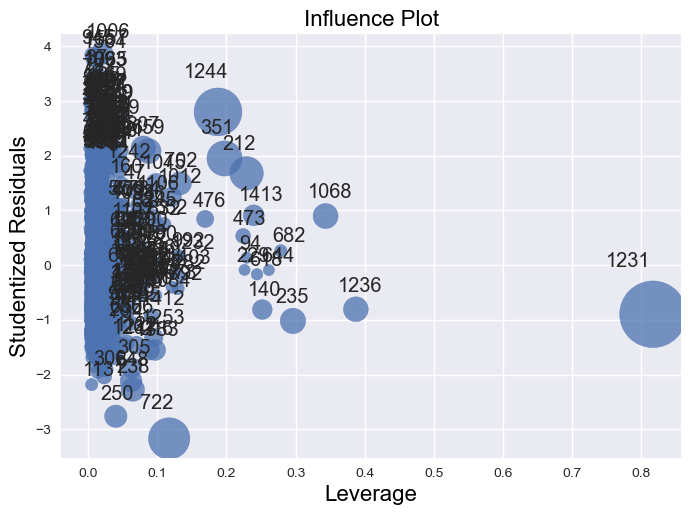

In [78]:
import seaborn as sns

results=linear_model

# Get different Variables for diagnostic 
residuals = results.resid 
fitted_value = results.fittedvalues 
stand_resids = results.resid_pearson 
influence = results.get_influence() 
leverage = influence.hat_matrix_diag 

# PLot different diagnostic plots 
plt.rcParams["figure.figsize"] = (20,15) 
fig, ax = plt.subplots(nrows=2, ncols=2) 

plt.style.use('seaborn-v0_8') 

# Residual vs Fitted Plot 
sns.scatterplot(x=fitted_value, y=residuals, ax=ax[0, 0]) 
ax[0, 0].axhline(y=0, color='grey', linestyle='dashed') 
ax[0, 0].set_xlabel('Fitted Values') 
ax[0, 0].set_ylabel('Residuals') 
ax[0, 0].set_title('Residuals vs Fitted Fitted') 

# Normal Q-Q plot 
sm.qqplot(residuals, fit=True, line='45',ax=ax[0, 1], c='#4C72B0') 
ax[0, 1].set_title('Normal Q-Q') 

# Scale-Location Plot 
sns.scatterplot(x=fitted_value, y=residuals, ax=ax[1, 0]) 
ax[1, 0].axhline(y=0, color='grey', linestyle='dashed') 
ax[1, 0].set_xlabel('Fitted values') 
ax[1, 0].set_ylabel('Sqrt(standardized residuals)') 
ax[1, 0].set_title('Scale-Location Plot') 

# Residual vs Leverage Plot 
sns.scatterplot(x=leverage, y=stand_resids, ax=ax[1, 1]) 
ax[1, 1].axhline(y=0, color='grey', linestyle='dashed') 
ax[1, 1].set_xlabel('Leverage') 
ax[1, 1].set_ylabel('Sqrt(standardized residuals)') 
ax[1, 1].set_title('Residuals vs Leverage Plot') 


plt.tight_layout() 
plt.show() 

# PLot Cook's distance plot 
sm.graphics.influence_plot(results, criterion="cooks") 
